# Figure 4(a,b) — path lengths and alignment averaged over Haar-random 3-qubit unitaries

`extra_fig6_parameter_trajectories_diffs.ipynb` measures, on the Figure 3 Toffoli problem, how far each
optimiser travels in parameter space and on the group and how well each step is aimed. One
target is one landscape, so this notebook repeats the measurement on `N_TARGETS` Haar-random
3-qubit unitaries, each from its own seeded initial pulse, on the same model at the same $L$
and initial spread, and averages the curves over the targets. The three quantities are those
of the Toffoli notebook, against the iteration number $m$:

- **in parameter space**, the cumulative path length
  $s_m = \sum_{j<m} \|\phi_{j+1}-\phi_j\|_2$ between consecutive iterates
  $\phi_j \in \mathbb R^{LK}$;
- **on the group**, the cumulative geodesic distance
  $g_m = \sum_{j<m} d_g\bigl(U(\phi_j), U(\phi_{j+1})\bigr)$ between the unitaries those
  iterates implement, with $d_g(U, U') = \|\mathrm{Log}_U(U')\|_F$ the geodesic distance of
  the bi-invariant metric on $\mathrm{SU}(8)$, global phase projected out;
- **the aim of each step**, the cosine $\cos\vartheta_m$ of the angle at $U_m$ between the
  geodesic direction to the target, $\mathrm{Log}_{U_m}V$, and the direction the step
  actually moved on the group, $\mathrm{Log}_{U_m}U_{m+1}$: $1$ for a step straight along
  the geodesic, $0$ for one orthogonal to it, negative for one that moves away.

The parameter space is that of `Parameters.free`: $K = 9$ columns per segment, the six
controls $\Omega_i\sigma^x_i$, $\Delta_i\sigma^z_i$ and the three $\sigma^z_i\sigma^z_j$ drift
couplings. GEOPE never moves the drift columns; the GRAPE rules do, since `Grape.update_step`
scatters its step over every free column, and the summary says how much of their path is
spent there.

In [1]:
from common import *
from scipy.stats import unitary_group

N_TARGETS = 50
L_STEPS = 120
SPREAD_RANDOM = 1.0  # initial spread, in units of pi
SPREAD_LABELS = {0.01: r"\pi/100", 1.0: r"\pi"}

#: Target ``i`` is drawn from ``np.random.default_rng(TARGET_SEED_BASE + i)``; its initial
#: pulse from seed ``i``, as the seeds of Figure 3 are drawn.
TARGET_SEED_BASE = 1000

#: How the heavy lines and the summary combine the targets: "mean", an average over
#: targets, or "median", the convention of Figure 3.
AGGREGATE = "mean"

#: `METHODS` names the optimisers as the legends do, `COLOURS` and `LABELS` as the
#: Figure 3 cache folders do; this maps the one onto the other.
STYLE_KEYS = {
    "GEOPE": "GEOPE",
    "LBFGS": "LBFGS",
    "Newton: TRM": "NewtonTRM",
    "Newton: RFO": "NewtonRFO",
    "Newton: SFN": "NewtonSaddleFree",
}

## The targets

Haar-random elements of $\mathrm U(8)$ from SciPy's `unitary_group`, one per seed. The
fidelity is projective, so the global phase of a target is immaterial and $\mathrm U(8)$
against $\mathrm{SU}(8)$ makes no difference. Each target gets its own initial pulse, drawn
from seed $i$ exactly as Figure 3 draws its seeds, so target and start are independent draws
and no two runs share either; every optimiser sees the same twenty pairs.

In [2]:
def random_target(index):
    """Haar-random target number ``index``."""
    return unitary_group.rvs(8, random_state=np.random.default_rng(TARGET_SEED_BASE + index))


TARGETS_RANDOM = [random_target(i) for i in range(N_TARGETS)]
overlap = [abs(np.trace(U)) / 8 for U in TARGETS_RANDOM]
print(
    f"{N_TARGETS} Haar-random targets; fidelity with the identity "
    f"from {min(overlap):.3f} to {max(overlap):.3f}"
)

50 Haar-random targets; fidelity with the identity from 0.026 to 0.326


## The trajectories

One block per optimiser under `cache/traj`, tagged `traj_HAAR3_…`: run $i$ of a block is
target $i$ from its own initial pulse, and the target matrix is stored with the run so that
its unitaries can be rebuilt later. The blocks are extended rather than replaced, so raising
`N_TARGETS` computes only the new targets. The logged columns are exactly `Parameters.free`,
as in the Toffoli notebook, and `metrics` reduces each trajectory to its parameter-space
statistics. The builder is `common._build_trajectory` with the target made explicit; a fresh
model, and so a fresh compile, per target is the price of a target per run.

In [3]:
def random_traj_config(method):
    """The block's cache key: the Extra Figure 6 config with the Toffoli swapped for the Haar targets."""
    cfg = {
        "tag": f"traj_HAAR3_L{L_STEPS}_{spread_slug(SPREAD_RANDOM)}_{method}",
        "kind": "fig8-random-unitary-trajectories",
        "gate": "HAAR3",
        "target_seed_base": TARGET_SEED_BASE,
        "steps": L_STEPS,
        "method": method,
        "config": repr(METHODS[method]),
        "spread": float(SPREAD_RANDOM),
        "n_qubits": 3,
        "columns": "proj+drift",
        "max_steps": MAX_STEPS,
        "precision": PRECISION,
    }
    if method == "GEOPE":
        cfg["geope_max_step"] = GEOPE_MAX_STEP
    return cfg


def build_trajectory(method, target):
    """An optimiser for ``target`` whose history logs every free column of each iterate."""
    params = make_parameters(3, L_STEPS, target, spread=SPREAD_RANDOM)
    free = np.asarray(params.proj_drift_indices, dtype=bool)
    flag = {"gs": False}

    def logging_fn(opt):
        row = {
            "phi": np.real(np.array(opt.params.parameters))[:, free].ravel(),
            "fidelities": float(opt.params.fidelity),
            "gs": flag["gs"],
        }
        flag["gs"] = False
        return row

    history = History(logging_fn=logging_fn)
    if method == "GEOPE":
        optimiser = Geope(params, history=history)
        inner = optimiser.gram_schmidt

        def gram_schmidt(coeffs):
            flag["gs"] = True
            return inner(coeffs)

        optimiser.gram_schmidt = gram_schmidt
    else:
        optimiser = Grape(params, precision=PRECISION, history=history)
    return params, optimiser


def optimise(optimiser, config):
    """Dispatch to whichever of the two ``optimize`` signatures applies, as `common` does."""
    if isinstance(optimiser, Geope):
        return optimiser.optimize(
            max_steps=MAX_STEPS, precision=PRECISION, line_search=config,
            max_step_size=GEOPE_MAX_STEP,
        )
    return optimiser.optimize(max_steps=MAX_STEPS, optimizer=config)


def random_trajectory_block(method, n_targets, verbose=True):
    """``[{"phi", "fid", "gs", "target"}, ...]``: run ``i`` on target ``i`` from pulse seed ``i``."""
    cfg = random_traj_config(method)
    npz_path, json_path = cache_paths(cfg, "traj")
    stored = cache_load(npz_path) or {}
    have = int(stored.get("n_runs", np.array(0)))
    runs = [
        {k: stored[f"{k}_{s}"] for k in ("phi", "fid", "gs", "target")} for s in range(have)
    ]
    config = METHODS[method]
    for index in range(have, n_targets):
        target = random_target(index)
        params, optimiser = build_trajectory(method, target)
        reinit(optimiser, random_pulse(params, np.random.default_rng(index), SPREAD_RANDOM))
        optimiser.history.reset()
        optimiser.history.record(optimiser)
        t0 = time.perf_counter()
        optimise(optimiser, config)
        h = optimiser.history
        runs.append(
            {
                "phi": np.stack(h.phi),
                "fid": np.asarray(h.fidelities),
                "gs": np.asarray(h.gs, dtype=bool),
                "target": target,
            }
        )
        arrays = {"n_runs": np.array(len(runs))}
        for s, r in enumerate(runs):
            arrays.update({f"{k}_{s}": v for k, v in r.items()})
        cache_save(npz_path, json_path, cfg, arrays)
        if verbose:
            print(
                f"  {cfg['tag']} target {index}: {len(h.fidelities) - 1} steps "
                f"{time.perf_counter() - t0:.1f}s 1-F {1 - h.fidelities[-1]:.1e}",
                flush=True,
            )
    return runs[:n_targets]


traj = {method: random_trajectory_block(method, N_TARGETS, verbose=False) for method in METHODS}
table = pd.DataFrame(
    [
        {"method": m, "target": i, **metrics(r)}
        for m, runs in traj.items()
        for i, r in enumerate(runs)
    ]
)
assert (table.disp <= table.excursion + 1e-12).all()
assert (table.excursion <= table.path + 1e-12).all()

## The same paths on the group

What the blocks log is exactly `Parameters.free`, so `manifold.compute_point` on each
stored row is the unitary that iterate implements. The chart depends on the model and not
on the target, so one jitted map serves every target; the target enters only through
`manifold.log` and `manifold.fidelity`, and is passed in per run. The fidelity of every
rebuilt unitary is checked against the one the optimiser recorded. At each $U_m$,
`manifold.log` gives the tangent to $U_{m+1}$, whose norm is $d_g(U_m, U_{m+1})$, and to the
target; $\cos\vartheta_m$ is their normalised Frobenius inner product. The geodesic
displacement $d_g(U_0, U_n)$ and the length $d_g(U_0, V)$ of the geodesic from the initial
unitary straight to the target complete the table, and the drift share is the part of the
parameter-space path length taken in the drift columns.

In [4]:
def group_geometry(steps, spread):
    """The model's manifold, with jitted maps from stored rows to unitaries and tangents."""
    params = make_parameters(3, steps, TARGETS_RANDOM[0], spread=spread)  # any target: the chart is target-free
    Geope(params)  # writes the drift columns, as the trajectory runs did
    manifold = params.manifold
    k_free = int(params.proj_drift_indices.sum())

    @jax.jit
    def unitaries(phi):
        free = jnp.asarray(phi.reshape(phi.shape[0], steps, k_free), dtype=jnp.complex128)
        return jax.vmap(manifold.compute_point)(free)

    @jax.jit
    def fidelities(points, target):
        return jax.vmap(lambda u: manifold.fidelity(u, target))(points)

    @jax.jit
    def distance(x, y):
        return jnp.sqrt(2.0 * manifold.distance2(x, y))

    @jax.jit
    def alignments(points, target):
        """cos of the angle at U_m between the geodesic to the target and the step taken."""

        def one(u, u_next):
            to_target = manifold.log(u, target)
            taken = manifold.log(u, u_next)
            scale = jnp.linalg.norm(to_target) * jnp.linalg.norm(taken)
            defined = scale > 1e-12  # a step that did not move, or a start on the target
            cosine = jnp.real(jnp.vdot(to_target, taken)) / jnp.where(defined, scale, 1.0)
            return jnp.where(defined, cosine, jnp.nan)

        return jax.vmap(one)(points[:-1], points[1:])

    return dict(
        unitaries=unitaries,
        fidelities=fidelities,
        step_distances=jax.jit(lambda points: jax.vmap(distance)(points[:-1], points[1:])),
        alignments=alignments,
        distance=distance,
        drift_columns=np.asarray(params.drift_indices_projdrift_basis, dtype=bool),
    )


def geodesic_metrics(run, geometry):
    """One run's per-step geodesic distances and alignments, and its scalar group statistics."""
    target = jnp.asarray(run["target"])
    points = geometry["unitaries"](run["phi"])
    rebuilt = np.asarray(geometry["fidelities"](points, target))
    assert np.abs(rebuilt - run["fid"]).max() < 1e-8, "stored columns do not rebuild the iterate"
    d = np.asarray(geometry["step_distances"](points))
    cos = np.asarray(geometry["alignments"](points, target))
    return d, cos, {
        "geo_path": float(d.sum()),
        "geo_disp": float(geometry["distance"](points[0], points[-1])),
        "geo_start_to_target": float(geometry["distance"](points[0], target)),
        "geo_max_step": float(d.max()),
        "align_mean": float(np.nanmean(cos)),
        "align_first": float(cos[0]),
    }


def drift_share(run, drift_columns, steps):
    """The share of the parameter-space path length taken in the drift columns."""
    d = np.diff(run["phi"].reshape(run["phi"].shape[0], steps, -1), axis=0)
    total = np.linalg.norm(d.reshape(d.shape[0], -1), axis=1).sum()
    drift = np.linalg.norm(d[:, :, drift_columns].reshape(d.shape[0], -1), axis=1).sum()
    return float(drift / total) if total > 0 else 0.0


geometry = group_geometry(L_STEPS, SPREAD_RANDOM)
geo, align = {}, {}
rows = []
for method, runs in traj.items():
    geo[method], align[method] = [], []
    for index, run in enumerate(runs):
        distances, cosines, scalars = geodesic_metrics(run, geometry)
        geo[method].append(distances)
        align[method].append(cosines)
        rows.append(
            {
                "method": method, "target": index, **scalars,
                "drift_share": drift_share(run, geometry["drift_columns"], L_STEPS),
            }
        )
table = table.merge(pd.DataFrame(rows), on=["method", "target"])
table["geo_tortuosity"] = table.geo_path / table.geo_disp
assert (table.geo_disp <= table.geo_path + 1e-9).all()

## Summary

Per method: the fraction of targets reached to $1-F<10^{-9}$ within the budget, then the
`AGGREGATE` over targets of the iterations and of the same four statistics in each space —
the path length ($s_n$, $g_n$), the displacement ($\|\phi_n-\phi_0\|$, $d_g(U_0,U_n)$), their
ratio (the tortuosity) and the longest single step — then of each run's mean $\cos\vartheta_m$
and of its first step's, the drift share of the parameter path, and GEOPE's Gram–Schmidt
fallback moves. With a random target and a random start, the geodesic from the initial
unitary straight to the target, $d_g(U_0, V)$, now varies from run to run; its range is
printed above the table, and no path that reaches its target can be shorter than it.

In [5]:
summary = table.groupby("method", sort=False).agg(
    converged=("converged", "mean"),
    iters=("iters", AGGREGATE),
    path=("path", AGGREGATE),
    disp=("disp", AGGREGATE),
    tortuosity=("tortuosity", AGGREGATE),
    max_step=("max_step", AGGREGATE),
    geo_path=("geo_path", AGGREGATE),
    geo_disp=("geo_disp", AGGREGATE),
    geo_tortuosity=("geo_tortuosity", AGGREGATE),
    geo_max_step=("geo_max_step", AGGREGATE),
    align_mean=("align_mean", AGGREGATE),
    align_first=("align_first", AGGREGATE),
    drift_share=("drift_share", AGGREGATE),
    n_gs=("n_gs", AGGREGATE),
)
start = table.geo_start_to_target
print(
    f"L = {L_STEPS}, spread {SPREAD_RANDOM:g} pi, {N_TARGETS} Haar-random targets, {AGGREGATE} over "
    f"targets; d_g(U_0, V) {getattr(start, AGGREGATE)():.3f} (runs {start.min():.3f} to {start.max():.3f})"
)
print(f"  {'':26s}{'parameter space':^38s}{'group':^36s}{'cos vartheta':^16s}")
print(
    f"  {'method':12s}{'conv':>7s}{'iters':>7s}"
    f"{'path':>10s}{'disp':>10s}{'tort.':>8s}{'max step':>10s}"
    f"{'path':>9s}{'disp':>9s}{'tort.':>8s}{'max step':>10s}"
    f"{'mean':>8s}{'first':>8s}{'drift':>8s}{'GS':>5s}"
)
for method in METHODS:
    row = summary.loc[method]
    print(
        f"  {method:12s}{row.converged * N_TARGETS:4.0f}/{N_TARGETS:<2d}{row.iters:7.0f}"
        f"{row.path:10.4g}{row.disp:10.4g}{row.tortuosity:8.2f}{row.max_step:10.3g}"
        f"{row.geo_path:9.3g}{row.geo_disp:9.3g}{row.geo_tortuosity:8.2f}"
        f"{row.geo_max_step:10.3g}{row.align_mean:8.2f}{row.align_first:8.2f}"
        f"{row.drift_share:8.2f}{row.n_gs:5.1f}"
    )

L = 120, spread 1 pi, 50 Haar-random targets, mean over targets; d_g(U_0, V) 5.089 (runs 4.424 to 5.789)
                                       parameter space                           group                  cos vartheta  
  method         conv  iters      path      disp   tort.  max step     path     disp   tort.  max step    mean   first   drift   GS
  GEOPE         50/50     15    0.8289    0.7573    1.09    0.0913     5.42     5.01    1.08     0.607    1.00    1.00    0.00  0.0
  LBFGS         50/50     14     2.794     1.692    1.69      1.31     15.9     5.13    3.07      5.01    0.63   -0.03    0.53  0.0
  Newton: TRM   50/50     26     256.7     202.4    1.49       188     27.4     5.05    5.44      5.24    0.46    0.02    0.53  0.0
  Newton: RFO   50/50     23     113.3     93.72    1.46      88.8     20.6        5    4.11      5.03    0.60    0.03    0.54  0.0
  Newton: SFN   50/50     36       206       129    2.24       119       22        5    4.40      4.84    0.35   -0.

## Figure — path lengths and alignment against iteration, averaged over targets

Left, the parameter-space path length $s_m$; middle, the cumulative geodesic distance $g_m$;
right, the alignment $\cos\vartheta_m$ of step $m$ with the geodesic to its target. Each faint
line is one target and the heavy line the `AGGREGATE` over targets at each iteration. For
the two lengths the curves are edge-padded as in Figure 3, so that a run which has converged
holds its final length rather than dropping out, and each heavy line runs to the last
iteration any target took; both length axes are logarithmic, so iteration 0, where every
path is zero, is not drawn. The dotted line in the middle panel is the `AGGREGATE` over runs
of $d_g(U_0, V)$, the geodesic from the initial unitary straight to its target. A converged
run takes no further steps, so the alignment is aggregated over the targets still running
at that iteration, and the dotted line at zero separates steps that move towards the target
from steps that move away.

figures/fig4ab_random_path_lengths_alignment_L120_spread1pi.pdf


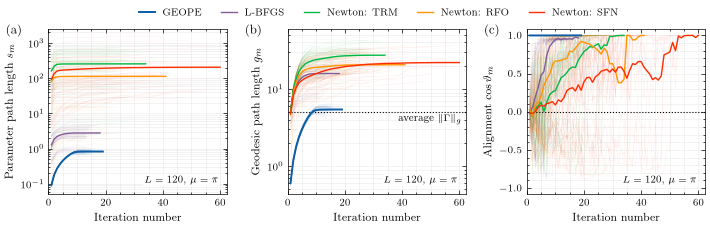

In [6]:
AGGREGATORS = {"mean": (np.mean, np.nanmean), "median": (np.median, np.nanmedian)}


def aggregate_over_runs(curves):
    """Elementwise `AGGREGATE` over runs, edge-padded to the longest as `median_over_runs` is."""
    longest = max(c.size for c in curves)
    padded = np.array([np.pad(c, (0, longest - c.size), mode="edge") for c in curves])
    return AGGREGATORS[AGGREGATE][0](padded, axis=0)


def aggregate_of_running(curves):
    """Elementwise `AGGREGATE` over the runs that still have a value at each index: no padding."""
    longest = max(c.size for c in curves)
    padded = np.full((len(curves), longest), np.nan)
    for row, c in zip(padded, curves):
        row[: c.size] = c
    return AGGREGATORS[AGGREGATE][1](padded, axis=0)


def path_lengths(run):
    """Cumulative parameter-space path length $s_m$ at every iterate, zero at the start."""
    steps = np.linalg.norm(np.diff(run["phi"], axis=0), axis=1)
    return np.concatenate([[0.0], np.cumsum(steps)])


def geodesic_lengths(distances):
    """Cumulative geodesic distance $g_m$ from one run's per-step distances, zero at the start."""
    return np.concatenate([[0.0], np.cumsum(distances)])


def draw_lengths(ax, curves_by_method):
    """Cumulative length against iteration, the aggregate over faint individual runs, from step 1."""
    for method, curves in curves_by_method.items():
        for y in curves:
            ax.semilogy(np.arange(1, y.size), y[1:], color=COLOURS[STYLE_KEYS[method]], **FAINT)
    for method, curves in curves_by_method.items():
        y = aggregate_over_runs(curves)
        ax.semilogy(np.arange(1, y.size), y[1:], **method_style(STYLE_KEYS[method]))
    ax.set_xlabel("Iteration number")
    ax.grid(alpha=0.25, which="both", lw=0.4)


def draw_alignment(ax, curves_by_method):
    """cos vartheta of step m at iteration m, the aggregate over the targets still running."""
    for method, curves in curves_by_method.items():
        for y in curves:
            ax.plot(np.arange(1, y.size + 1), y, color=COLOURS[STYLE_KEYS[method]], **FAINT)
    for method, curves in curves_by_method.items():
        y = aggregate_of_running(curves)
        ax.plot(np.arange(1, y.size + 1), y, **method_style(STYLE_KEYS[method]))
    ax.axhline(0.0, color="black", ls=":", lw=0.8, zorder=2)
    ax.set_ylim(-1.08, 1.08)
    ax.set_xlabel("Iteration number")
    ax.grid(alpha=0.25, which="both", lw=0.4)


fig, (ax_param, ax_group, ax_align) = plt.subplots(1, 3, figsize=(TWO_COLUMN, 2.1), sharex=True)
draw_lengths(ax_param, {m: [path_lengths(r) for r in runs] for m, runs in traj.items()})
draw_lengths(ax_group, {m: [geodesic_lengths(d) for d in geo[m]] for m in METHODS})
draw_alignment(ax_align, {m: align[m] for m in METHODS})
floor = getattr(table.geo_start_to_target, AGGREGATE)()
ax_group.axhline(floor, color="black", ls=":", lw=0.8, zorder=2)
ax_group.annotate(
    r"average $\Vert \Gamma \Vert_g$", (0.97, floor), xycoords=("axes fraction", "data"),
    ha="right", va="top", fontsize=ANNOTATION_SIZE, xytext=(0, -1.5), textcoords="offset points",
)
longest = max(r["phi"].shape[0] - 1 for runs in traj.values() for r in runs)
ax_param.set_xlim(0, 1.04 * longest)
ax_param.set_ylabel(r"Parameter path length $s_m$")
ax_group.set_ylabel(r"Geodesic path length $g_m$")
ax_align.set_ylabel(r"Alignment $\cos\vartheta_m$")
# Panel letters top left and one legend above the panels, as in Figure 3.
for ax, letter in zip((ax_param, ax_group, ax_align), "abc"):
    ax.text(  # outside the axes, to the left of the tick labels, as in Figure 3
        -0.24, 1.03, rf"({letter})", transform=ax.transAxes, ha="left", va="top",
        fontsize=PANEL_LABEL_SIZE, zorder=5,
    )
    ax.text(
        0.95, 0.07, rf"$L={L_STEPS}$, $\mu={SPREAD_LABELS[SPREAD_RANDOM]}$", transform=ax.transAxes, ha="right",
        fontsize=ANNOTATION_SIZE, zorder=5,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.2),
    )
handles, labels = ax_param.get_legend_handles_labels()
fig.legend(
    handles, labels, loc="lower center", ncol=5, frameon=False,
    bbox_to_anchor=(0.53, 1.0), handlelength=1.6,
)
fig.subplots_adjust(left=0.065, right=0.99, top=0.985, bottom=0.2, wspace=0.34)
print(save_figure(fig, f"fig4ab_random_path_lengths_alignment_L{L_STEPS}_{spread_slug(SPREAD_RANDOM)}"))
plt.show()